# 02 // Read quality control

This notebook:
- Removes adapter sequences, low-quality read ends and poor read pairs.
- Keeps track of how many read pairs every sample keeps.

We use [fastp](https://github.com/OpenGene/fastp), through the QIIME 2 plugin `q2-fastp` (`qiime fastp process-seqs`).

The settings are the same for every sample: 

| Step | Setting | ... |
|---|---|---|
| Adapter trimming | on (fastp default) | fastp finds adapters where the two reads overlap and cuts them off |
| Trim low-quality 3' ends (`--p-cut-tail`) | window 4 bp, mean quality 20 | A 4 bp window moves in from the end of the read and cuts until its mean quality is at least 20 |
| Read quality filter | fastp defaults | A read is removed if more than 40% of its bases have quality below 15, or if it has more than 5 unknown bases (N) |
| Minimum read length (`--p-length-required`) | 75 bp | Read pairs with a read shorter than 75 bp after trimming are removed: the Madagascar and Guinea-Bissau reads were already filtered at 75 bp, so all studies end up with the same minimum |
| Duplicate removal | off | Duplicates could be real abundance of taxa which we don't want to ignore |

NOTE re: naming: Due to the large size, the heavy steps need to be submitted as Slurm jobs, in batches, as suggested by the project instructions too. A batch is set as one country with one read length (for example, CMR_126) so that each batch comes from one sequencing setup and the quality plots will be easy to read. 

**Inputs:** the raw reads, and `results/01_sample_overview.tsv` from notebook 01.

**Outputs:**
- quality-controlled reads, in the QIIME 2 cache in scratch (keys `qc_reads_<batch>`)
- `results/02_batches/`: the sample list of each batch
- `results/02_sample_overview.tsv`: the overview from notebook 01 + read pairs after quality control
- `results/02_read_pairs_retained.png`, `results/02_quality_before_after.png`

## Setup

In [1]:
import os
import sys
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Work from the repository root (this notebook is one level inside it, in notebooks/)
if Path.cwd().name == "notebooks":
    os.chdir("..")
print("Working directory:", Path.cwd())

# This makes qiime available to "!" shell commands
env_bin = str(Path(sys.executable).parent)
os.environ["PATH"] = env_bin + os.pathsep + os.environ["PATH"]

# Small outputs go to results/, large outputs stay in scratch
RESULTS = Path("results")
SCRATCH = Path("/cluster/scratch") / os.environ["USER"] / "africangut"
CACHE = SCRATCH / "qiime_cache"        # QIIME 2 cache 
QC_DIR = SCRATCH / "02_read_qc"        # one folder per batch, with the fastp reports

# Urbanization levels in order, and one colour per level (the same as in notebook 01)
URBANIZATION_ORDER = ["Urban", "Peri-urban", "Peri-rural", "Hinterland"]
COLOURS = {"Urban": "#2a78d6", "Peri-urban": "#eb6834", "Peri-rural": "#1baf7a", "Hinterland": "#eda100"}

# Plot style:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

Working directory: /cluster/home/mozdemir/microbiomes


## 1. Batches

Starting from the sample overview of notebook 01 we give every sample a batch name made of its country and read length, as explained above. Each batch gets a sample list in `results/02_batches/`, which the Slurm job will use to pick out its samples.

In [2]:
# Sample overview from notebook 01: one row per sample
overview = pd.read_csv(RESULTS / "01_sample_overview.tsv", sep="\t", index_col="sample_id")
overview["urbanization"] = pd.Categorical(overview["urbanization"], categories=URBANIZATION_ORDER)

# Batch name = country + read length
overview["batch"] = overview["country_iso3"] + "_" + overview["read_length"].astype(str)

# Number of samples and raw read pairs (in millions) per batch
overview.groupby("batch").agg(samples=("raw_read_pairs", "size"),
                              raw_read_pairs_millions=("raw_read_pairs", lambda x: round(x.sum() / 1e6)))

,samples,raw_read_pairs_millions
batch,,
CMR_126,12,114
GNB_101,6,127
GNB_151,10,251
MDG_101,17,426
TZA_151,8,138


In [3]:
# One sample list per batch: table with the sample IDs and the batch name
BATCH_DIR = RESULTS / "02_batches"
BATCH_DIR.mkdir(exist_ok=True)

for batch, samples in overview.groupby("batch"):
    samples[["batch"]].to_csv(BATCH_DIR / f"{batch}.tsv", sep="\t", index_label="sample-id")

BATCHES = sorted(overview["batch"].unique())
print("Batches:", BATCHES)

Batches: ['CMR_126', 'GNB_101', 'GNB_151', 'MDG_101', 'TZA_151']


**Test samples.** Before processing everything, we run the same job on three small samples from three different sequencing setups: Cameroon (126 bp, HiSeq), Tanzania (151 bp, NovaSeq, untrimmed) and Madagascar (101 bp, already trimmed by the original authors).

In [4]:
# The smallest sample (fewest raw read pairs) of three different batches
smallest = overview.sort_values("raw_read_pairs").groupby("batch").head(1)
test_samples = smallest[smallest["batch"].isin(["CMR_126", "TZA_151", "MDG_101"])].copy()

# Saving them as the sample list of a batch called "test"
test_samples["batch"] = "test"
test_samples[["batch"]].to_csv(BATCH_DIR / "test.tsv", sep="\t", index_label="sample-id")
test_samples[["country_iso3", "read_length", "raw_read_pairs"]]

,country_iso3,read_length,raw_read_pairs
sample_id,,,
SRR7658613,MDG,101,3125525
SRR9293007,CMR,126,7825668
SRR13348807,TZA,151,11355875


## 2. Raw reads into a QIIME 2 cache (run once)

This step was included to help save some time and disk space working with our very large file. Everytime QIIME2 reads a `.qza` zip archive it needs tp unpack our 150GB reads, so we keep a QIIME 2 cache where artifacts are stored already unpacked in scratch. All batch jobs also read them from there, and they also save their results in the cache.

In [5]:
!cat scripts/02_cache_raw_reads.sh

#!/bin/bash
#SBATCH --job-name=02_cache_raw_reads
#SBATCH --account=public
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=1
#SBATCH --mem-per-cpu=8G
#SBATCH --time=06:00:00
#SBATCH --output=logs/%x_%j.out
#SBATCH --error=logs/%x_%j.err

# Store the raw reads once in a QIIME 2 cache in scratch.
# A cache keeps artifacts unpacked, so the batch jobs of notebook 02 can read the raw reads
# without each of them unpacking the 150 GB .qza file again.
# Used by notebooks/02_read_qc.ipynb
# Usage, from the repository root: sbatch scripts/02_cache_raw_reads.sh

set -euo pipefail

CACHE="/cluster/scratch/$USER/africangut/qiime_cache"

# Temporary files in scratch, deleted when the job ends
export TMPDIR="/cluster/scratch/$USER/africangut/tmp/$SLURM_JOB_ID"
mkdir -p "$TMPDIR"
trap 'rm -rf "$TMPDIR"' EXIT

# Activate the course environment ('set -eu' is relaxed while ~/.bashrc is sourced)
set +eu; source ~/.bashrc; conda activate rachis-moshpit-2026.7; set -eu

# Create the (empty) cache folder, unless

In [6]:
# Submitting the cache job, unless the cache already holds the raw reads
if (CACHE / "keys" / "raw_reads").exists():
    print("The raw reads are already in the cache.")
else:
    !sbatch scripts/02_cache_raw_reads.sh

Submitted batch job 16961157


In [9]:
# Checking the job in my queue
!squeue --me

             JOBID PARTITION     NAME     USER ST       TIME  NODES NODELIST(REASON)


## 3. Test run on three samples

The quality-control job for one batch --> selects the batch's samples from the cached raw reads, runs fastp with the settings mentioned above, and exports fastp's report for every sample. 

In [5]:
!cat scripts/02_read_qc.sh

#!/bin/bash
#SBATCH --job-name=02_read_qc
#SBATCH --account=public
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=8
#SBATCH --mem-per-cpu=2G
#SBATCH --time=24:00:00
#SBATCH --output=logs/%x_%j.out
#SBATCH --error=logs/%x_%j.err

# Read quality control of one batch of samples with fastp.
# Used by notebooks/02_read_qc.ipynb (run scripts/02_cache_raw_reads.sh once before)
# Usage, from the repository root: sbatch scripts/02_read_qc.sh BATCH
#   BATCH = name of a sample list in results/02_batches/, for example CMR_126 or test

set -euo pipefail

BATCH="$1"
CACHE="/cluster/scratch/$USER/africangut/qiime_cache"
OUT_DIR="/cluster/scratch/$USER/africangut/02_read_qc/$BATCH"
mkdir -p "$OUT_DIR"
echo "Batch: $BATCH"

# Temporary files in scratch, deleted when the job ends
export TMPDIR="/cluster/scratch/$USER/africangut/tmp/$SLURM_JOB_ID"
mkdir -p "$TMPDIR"
trap 'rm -rf "$TMPDIR"' EXIT

# Activate the course environment ('set -eu' is relaxed while ~/.bashrc is sourced)
set +eu; source ~/.bashrc; co

In [6]:
# Submitting the test job, unless it has run already
if (QC_DIR / "test" / "fastp_reports").exists():
    print("The test has run already.")
else:
    !sbatch --job-name=02_read_qc_test scripts/02_read_qc.sh test

The test has run already.


In [7]:
!squeue --me

             JOBID PARTITION     NAME     USER ST       TIME  NODES NODELIST(REASON)
          16970965 normal.4h clean_st mozdemir  R       1:52      1 eu-a2p-504
          16970966 normal.4h clean_co mozdemir  R       1:52      1 eu-a2p-470
          16970967 normal.4h clean_ic mozdemir  R       1:52      1 eu-a2p-467


When the test job has finished, we read its fastp reports. This helper function turns the reports of one batch into a table with one row per sample. fastp counts single reads; a read pair is two reads, so we divide by 2.

In [7]:
def read_fastp_reports(batch):
    # Return a table with one row per sample, built from the fastp JSON reports of one batch
    rows = []
    for report_file in sorted((QC_DIR / batch / "fastp_reports").glob("*.json")):
        with open(report_file) as handle:
            report = json.load(handle)
        before = report["summary"]["before_filtering"]["total_reads"]
        removed = report["filtering_result"]
        rows.append({
            "sample_id": report_file.stem,                      # the file is named <sample_id>.json
            "batch": batch,
            "fastp_input_pairs": before // 2,
            "qc_read_pairs": report["summary"]["after_filtering"]["total_reads"] // 2,
            # Why reads were removed, as % of all reads that went into fastp
            "pct_too_short": 100 * removed["too_short_reads"] / before,
            "pct_low_quality": 100 * removed["low_quality_reads"] / before,
            "pct_too_many_N": 100 * removed["too_many_N_reads"] / before,
        })
    return pd.DataFrame(rows).set_index("sample_id")


test_results = read_fastp_reports("test")
test_results["pct_retained"] = 100 * test_results["qc_read_pairs"] / test_results["fastp_input_pairs"]
test_results.round(1)

,batch,fastp_input_pairs,qc_read_pairs,pct_too_short,pct_low_quality,pct_too_many_N,pct_retained
sample_id,,,,,,,
SRR13348807,test,11355875,11138174,0.2,1.7,0.0,98.1
SRR7658613,test,3125525,3113971,0.2,0.1,0.0,99.6
SRR9293007,test,7825668,7718695,1.4,0.0,0.0,98.6


`fastp_input_pairs` are equal the raw read pairs from notebook 01, most read pairs are kept.

## 4. Running all batches

Running the below cell submits one job per batch. But they run in parallel. The largest one takes a few hours. 

In [8]:
# Submitting one job per batch, skipping batches that have run already
for batch in BATCHES:
    if (QC_DIR / batch / "fastp_reports").exists():
        print(batch, "has run already")
    else:
        !sbatch --job-name=02_read_qc_{batch} scripts/02_read_qc.sh {batch}

CMR_126 has run already
GNB_101 has run already
GNB_151 has run already
MDG_101 has run already
TZA_151 has run already


In [9]:
!squeue --me

             JOBID PARTITION     NAME     USER ST       TIME  NODES NODELIST(REASON)


## 5. Read pairs after quality control

This adds the next column to the read-tracking table. As before, we flag samples but do not remove them. here, samples that keep less than 80% of their read pairs are flagged.

In [10]:
# fastp results of all batches in one table
qc = pd.concat([read_fastp_reports(batch) for batch in BATCHES])

# Adding the read pairs after QC to the overview and computing the % of raw read pairs kept
overview["qc_read_pairs"] = qc["qc_read_pairs"]
overview["pct_retained_qc"] = 100 * overview["qc_read_pairs"] / overview["raw_read_pairs"]

# Flagging samples that keep less than 80% of their read pairs
RETENTION_FLAG = 80
overview["low_retention_qc"] = overview["pct_retained_qc"] < RETENTION_FLAG

overview["pct_retained_qc"].describe().round(1)

count    53.0
mean     99.1
std       1.0
min      95.4
25%      98.5
50%      99.6
75%      99.8
max      99.9
Name: pct_retained_qc, dtype: float64

In [11]:
# Flagged samples
overview[overview["low_retention_qc"]][["batch", "raw_read_pairs", "qc_read_pairs", "pct_retained_qc"]]

,batch,raw_read_pairs,qc_read_pairs,pct_retained_qc
sample_id,,,,


In [12]:
# average % of reads per batch, for each reason why they were removed
qc.groupby("batch")[["pct_too_short", "pct_low_quality", "pct_too_many_N"]].mean().round(2)

,pct_too_short,pct_low_quality,pct_too_many_N
batch,,,
CMR_126,1.91,0.05,0.01
GNB_101,0.23,0.12,0.00
GNB_151,0.01,0.33,0.00
MDG_101,0.14,0.07,0.00
TZA_151,0.19,1.87,0.00


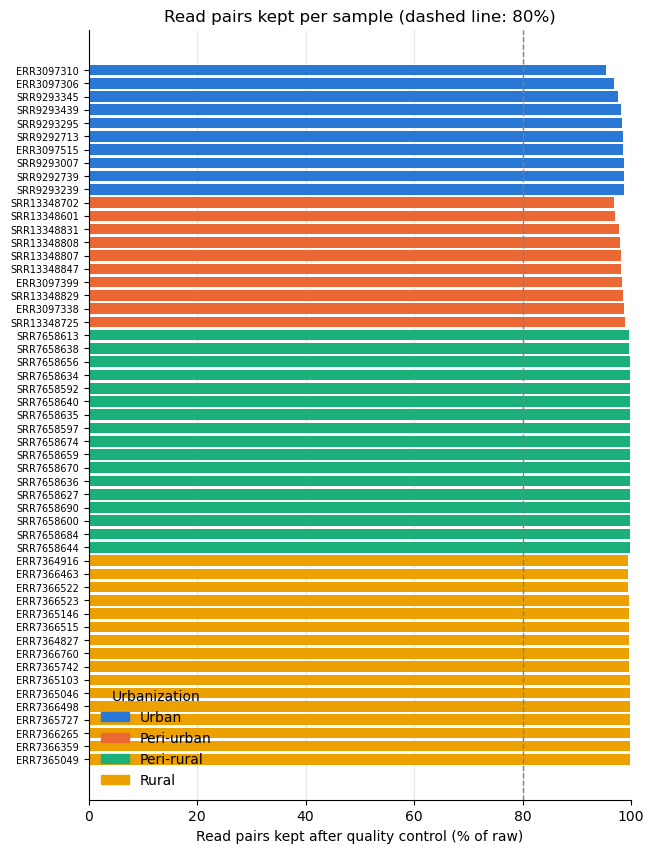

In [13]:
# Bar chart: % of raw read pairs kept per sample
plot_data = overview.sort_values(["urbanization", "pct_retained_qc"])
bar_colours = [COLOURS[level] for level in plot_data["urbanization"]]
# In plots, the "Hinterland" level is labelled "Rural"
plot_labels = {"Hinterland": "Rural"}

fig, ax = plt.subplots(figsize=(7, 10))
ax.barh(plot_data.index, plot_data["pct_retained_qc"], color=bar_colours, height=0.8)
ax.axvline(RETENTION_FLAG, color="grey", linestyle="--", linewidth=1)   # flag threshold
ax.invert_yaxis()                                                         # first level at the top
ax.set_xlim(0, 100)
ax.set_xlabel("Read pairs kept after quality control (% of raw)")
ax.set_title("Read pairs kept per sample (dashed line: 80%)")
ax.tick_params(axis="y", labelsize=7)
ax.grid(axis="x", color="0.9")
ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=c, label=plot_labels.get(level, level)) for level, c in COLOURS.items()],
          title="Urbanization", frameon=False, loc="lower left")

fig.savefig(RESULTS / "02_read_pairs_retained.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Quality before and after quality control

Since fastp records the mean quality at each position of the reads before and after filtering, for each batch we average these curves over its samples --> one column of panels per batch, forward reads (read 1) on top and reverse reads (read 2) below.

In [14]:
def mean_quality_curve(batch, read, stage):
    # Average over the samples of a batch of fastp's mean quality per position.
    # read: "read1" or "read2"; stage: "before_filtering" or "after_filtering"
    curves = []
    for report_file in (QC_DIR / batch / "fastp_reports").glob("*.json"):
        with open(report_file) as handle:
            report = json.load(handle)
        curves.append(report[f"{read}_{stage}"]["quality_curves"]["mean"])
    return pd.DataFrame(curves).mean()   # one value per position


fig, axes = plt.subplots(2, len(BATCHES), figsize=(3 * len(BATCHES), 6), sharey=True)

for col, batch in enumerate(BATCHES):
    for row, read in enumerate(["read1", "read2"]):
        ax = axes[row, col]
        before = mean_quality_curve(batch, read, "before_filtering")
        after = mean_quality_curve(batch, read, "after_filtering")
        ax.plot(range(1, len(before) + 1), before, color="0.6", linewidth=2, label="Before QC")
        ax.plot(range(1, len(after) + 1), after, color="#2a78d6", linewidth=2, label="After QC")
        ax.set_title(f"{batch}, {read}", fontsize=10)
        ax.grid(color="0.9")
        ax.set_axisbelow(True)
    axes[1, col].set_xlabel("Position in read (bp)")

axes[0, 0].set_ylabel("Mean quality (Phred)")
axes[1, 0].set_ylabel("Mean quality (Phred)")
axes[0, 0].legend(frameon=False, loc="lower left")

fig.savefig(RESULTS / "02_quality_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Saving the sample overview

Sample overview now contains overview from the previous notebook + the batch + the read pairs after QC + the % kept + the flags.
Next, notebook 03 will add the read pairs after host removal.

In [15]:
overview.to_csv(RESULTS / "02_sample_overview.tsv", sep="\t", index_label="sample_id")
overview.head()

,country_iso3,urbanization,read_length,raw_read_pairs,low_depth,batch,qc_read_pairs,pct_retained_qc,low_retention_qc
sample_id,,,,,,,,,
ERR3097306,CMR,Urban,126,8937217,False,CMR_126,8648650,96.771176,False
SRR9292713,CMR,Urban,126,10252447,False,CMR_126,10090796,98.423293,False
SRR9293345,CMR,Urban,126,8923296,False,CMR_126,8712245,97.634831,False
SRR9292739,CMR,Urban,126,9012176,False,CMR_126,8892146,98.668135,False
SRR9293007,CMR,Urban,126,7825668,False,CMR_126,7718695,98.633050,False
